# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

import re

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())

display(df.head())

Saving Lab_11_QnA_Dataset.csv to Lab_11_QnA_Dataset.csv
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
# 1. Lowercase and remove punctuation
df["question"] = df["question"].str.lower()
df["question"] = df["question"].apply(
    lambda x: re.sub(r"[^\w\s]", "", x)
)

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# 3. Convert words to numbers and add padding
X = pad_sequences(
    tokenizer.texts_to_sequences(df["question"]),
    padding="post"
)

# 4. Answers
y = df["answer_id"].values

# 5. Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: torch.Size([168, 11])
y shape: torch.Size([168])


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)

        self.rnn = nn.RNN(16, 32, batch_first=True)

        self.att = nn.Linear(32, 1)

        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        embedded = self.emb(x)

        output, _ = self.rnn(embedded)

        scores = self.att(output)

        # Ignore padding positions
        scores = scores.masked_fill(x.unsqueeze(-1) == 0, -1e9)

        weights = torch.softmax(scores, dim=1)

        context = (output * weights).sum(1)

        return self.fc(context), weights.squeeze(-1)


model = RNN()

print(model)

RNN(
  (emb): Embedding(227, 16)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):

    optimizer.zero_grad()

    predictions, weights = model(X)

    loss = nn.functional.cross_entropy(predictions, y)

    loss.backward()

    optimizer.step()

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

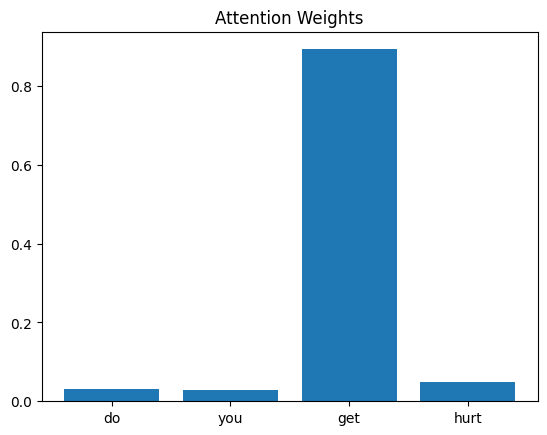

In [7]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Answer: The words with the highest attention weights generally appear important for understanding the questions. The model gives higher attention to words that carry more meaning and help identify the question's intent. However, the highest attention word may differ depending on the question.

Question: do you get hurt
Highest attention word: get


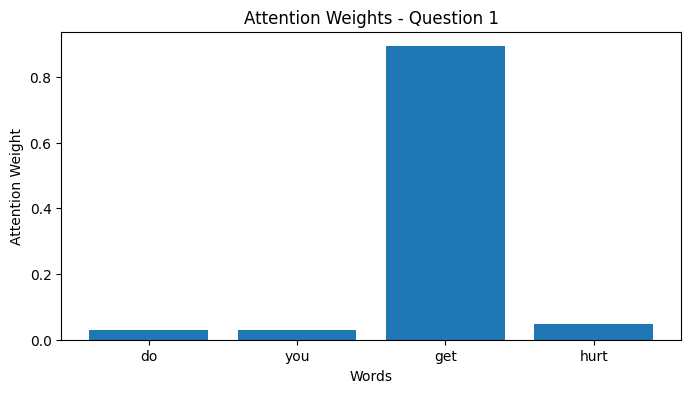

Question: do you have fingers
Highest attention word: fingers


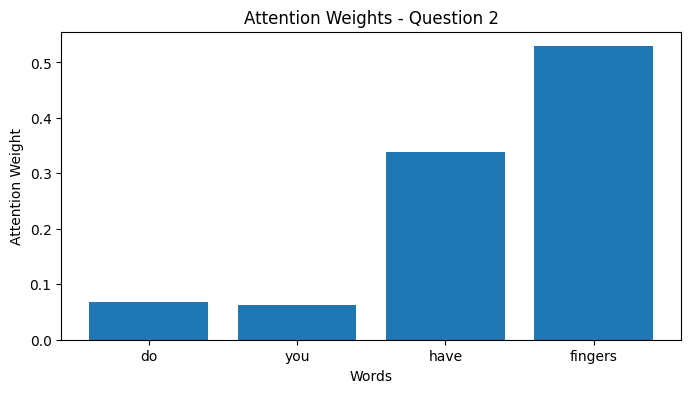

Question: do you ever breathe
Highest attention word: breathe


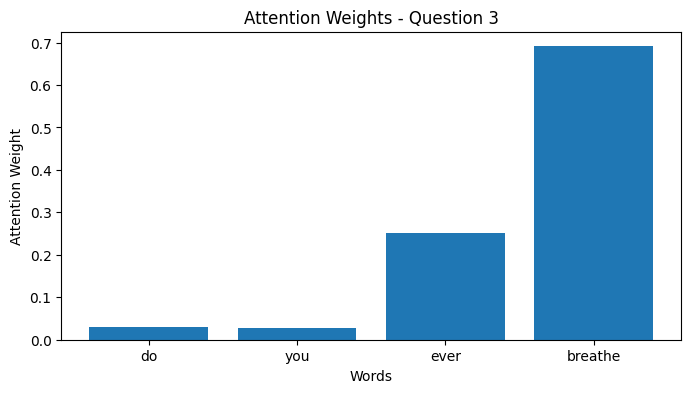

In [8]:
# Select three questions from the dataset
selected_questions = [0, 1, 2]

for i in selected_questions:

    question = df["question"].iloc[i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    # Find the word with the highest attention weight
    highest_index = attention_weights.index(max(attention_weights))
    highest_word = words[highest_index]

    print("Question:", question)
    print("Highest attention word:", highest_word)

    # Plot attention weights
    plt.figure(figsize=(8, 4))
    plt.bar(words, attention_weights)
    plt.title(f"Attention Weights - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Answer: The model may focus on different words when processing questions with similar meanings. For example, it may focus on "hurt" in the first question and "fingers" in the second question. This suggests that attention assigns weights to words based on their importance in each question, rather than focusing on the same words in every sentence.

Question: do you get hurt
Highest attention word: get


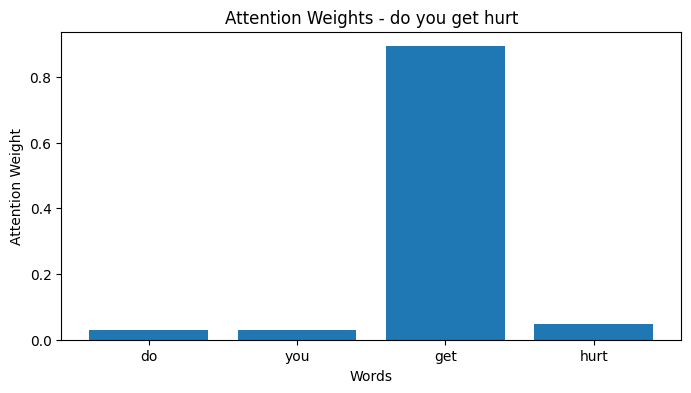

Question: do you have fingers
Highest attention word: fingers


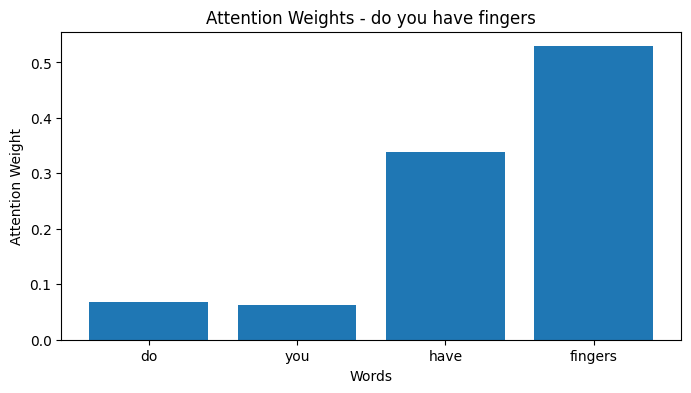

In [9]:
# Select two questions from the same answer group
same_group = df[df["answer_id"] == df["answer_id"].iloc[0]]

selected_indices = same_group.index[:2]

for i in selected_indices:

    question = df["question"].iloc[i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    highest_index = attention_weights.index(max(attention_weights))
    highest_word = words[highest_index]

    print("Question:", question)
    print("Highest attention word:", highest_word)

    # Plot attention weights
    plt.figure(figsize=(8, 4))
    plt.bar(words, attention_weights)
    plt.title(f"Attention Weights - {question}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()